# Rugged Mueller committor: full 10-coordinate training

The neural network receives all ten coordinates. The variational loss includes all ten input derivatives. Two-dimensional figures and the isocommittor analysis use the slice $x_3=\cdots=x_{10}=0$; all shooting trajectories evolve in ten dimensions.


In [1]:
from dataclasses import asdict
from functools import lru_cache
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from project_runtime import select_device

from committor_problem import (
    BoundaryConditionModel,
    CommittorModelNN,
    MetadynamicsConfig,
    MetadynamicsResult,
    ShootingConfig,
    TrainingConfig,
    committor_analysis,
    frozen_bias_weights,
    extract_isocommittor,
    metadynamics,
    plot_committor,
    plot_committor_histogram,
    plot_loss,
    predict,
    sample_isocommittor,
    train,
)

plt.rcParams.update({'font.size': 14})
torch.manual_seed(0)
device = select_device()
if device.type == 'cpu':
    torch.set_num_threads(min(4, torch.get_num_threads()))
print(f'Compute device: {device}; CPU threads: {torch.get_num_threads()}')
np.random.seed(0)
output_dir = Path.cwd() / 'outputs' / 'rugged_mueller_10d'
output_dir.mkdir(parents=True, exist_ok=True)

Compute device: cpu; CPU threads: 4


In [2]:
beta = 0.1
dimension = 10
gamma = 9.0
frequency = 5
sigma = 0.05
mueller_parameters = torch.tensor([
    [-200., -100., -170., 15.],
    [-1., -1., -6.5, 0.7],
    [0., 0., 11., 0.6],
    [-10., -10., -6.5, 0.7],
    [1., 0., -0.5, -1.],
    [0., 0.5, 1.5, 1.],
], dtype=torch.float64)

@lru_cache(maxsize=None)
def potential_parameters(device, dtype):
    return mueller_parameters.to(device=device, dtype=dtype)

def potential(x):
    amplitude, xx, xy, yy, cx, cy = potential_parameters(x.device, x.dtype)
    dx = x[:, 0:1] - cx
    dy = x[:, 1:2] - cy
    base = (amplitude * torch.exp(xx*dx**2 + xy*dx*dy + yy*dy**2)).sum(dim=1)
    rugged = gamma * torch.sin(2*frequency*torch.pi*x[:, 0]) * torch.sin(2*frequency*torch.pi*x[:, 1])
    confinement = x[:, 2:].square().sum(dim=1) / sigma**2
    return base + rugged + confinement

In [3]:
a = torch.tensor([-0.558, 1.441], dtype=torch.float64)
b = torch.tensor([0.623, 0.028], dtype=torch.float64)
radius = 0.1
boundary_margin = 0.02
boundary_sharpness = 1000.0

@lru_cache(maxsize=None)
def region_centers(device, dtype):
    return a.to(device=device, dtype=dtype), b.to(device=device, dtype=dtype)

def in_a(x):
    return (x[:, :2] - region_centers(x.device, x.dtype)[0]).square().sum(dim=1) <= radius**2

def in_b(x):
    return (x[:, :2] - region_centers(x.device, x.dtype)[1]).square().sum(dim=1) <= radius**2


def chi_a(x):
    distance_squared = (x[:, :2] - region_centers(x.device, x.dtype)[0]).square().sum(dim=1, keepdim=True)
    return 0.5 - 0.5 * torch.tanh(boundary_sharpness * (distance_squared - (radius + boundary_margin)**2))

def chi_b(x):
    distance_squared = (x[:, :2] - region_centers(x.device, x.dtype)[1]).square().sum(dim=1, keepdim=True)
    return 0.5 - 0.5 * torch.tanh(boundary_sharpness * (distance_squared - (radius + boundary_margin)**2))

qmodel = BoundaryConditionModel(
    CommittorModelNN(dimension, hidden_size=32), chi_a, chi_b,
)
# The benchmark network learns from all ten coordinates, with no input selector.
assert qmodel.network.linear0.in_features == dimension == 10
assert qmodel.network.active_dimensions is None
print(f'Network inputs: {qmodel.network.linear0.in_features}; parameters: {sum(p.numel() for p in qmodel.parameters())}')


Network inputs: 10; parameters: 2689


In [4]:
sampling_config = MetadynamicsConfig(
    time_step=1e-5,
    deposit_every=500,
    n_hills=2000,
    hill_height=5.0,
    hill_width=0.05,
    n_samples=210_000,
    sample_stride=1,
    seed=0,
    burn_in_steps=10_000,
    device="cpu",
)

In [5]:
# Training points are full 10D states. This cache is independent of network architecture.
# Its metadata prevents silently reusing data after changing the physical problem.
sampling_metadata = {
    'dimension': dimension, 'beta': beta, 'gamma': gamma,
    'frequency': frequency, 'sigma': sigma,
    'mueller_parameters': mueller_parameters.tolist(),
    'a': a.tolist(), 'b': b.tolist(), 'radius': radius,
    'sampling': {k: v for k, v in asdict(sampling_config).items()
                 if k not in ('device', 'log_every')},
}
training_data_path = output_dir / 'training_points.npz'
if training_data_path.exists():
    with np.load(training_data_path) as cached:
        if json.loads(str(cached['sampling_metadata'])) != sampling_metadata:
            raise ValueError('Cached training data do not match the problem/sampling settings. Use a new output directory.')
        samples = MetadynamicsResult(
            torch.from_numpy(cached['point_cloud'].copy()),
            torch.from_numpy(cached['hill_centers'].copy()),
        )
        points = torch.from_numpy(cached['training_points'].copy())
        weights = torch.from_numpy(cached['sample_weights'].copy())
        training_data_source = str(cached['data_source'])
    print(f'Loaded full-state training data from {training_data_path}')
else:
    initial_point = torch.zeros(dimension, dtype=torch.float64)
    initial_point[:2] = a
    samples = metadynamics(potential, initial_point, beta, sampling_config)
    keep = ~in_a(samples.points) & ~in_b(samples.points)
    points = samples.points[keep]
    weights = frozen_bias_weights(
        points.to(device=device, dtype=torch.float32), samples.hill_centers,
        beta, sampling_config,
    ).cpu()
    training_data_source = 'Generated by metadynamics in this notebook'
    np.savez_compressed(
        training_data_path, point_cloud=samples.points.cpu().numpy(),
        training_points=points.cpu().numpy(), sample_weights=weights.numpy(),
        hill_centers=samples.hill_centers.cpu().numpy(),
        sampling_metadata=json.dumps(sampling_metadata, sort_keys=True),
        data_source=training_data_source,
    )

assert samples.points.shape == (sampling_config.n_samples, dimension)
assert points.ndim == 2 and points.shape[1] == dimension
assert not (in_a(points) | in_b(points)).any()
assert weights.shape == (len(points),) and torch.isfinite(weights).all()
train_data = points.float()
print(f'Training data shape: {tuple(train_data.shape)}')
print(f'Coordinate standard deviations: {train_data.std(dim=0).tolist()}')
print(f'Importance-weight effective sample size: {weights.sum().square() / weights.square().sum():.0f}')

# Training additionally refreshes coordinates 3-10 independently per minibatch;
# see training_config below. The network and its Dirichlet gradient remain 10D.


Loaded full-state training data from /home/avikgdas/amsc665_hw/project2/outputs/rugged_mueller_10d/training_points.npz
Training data shape: (206463, 10)
Coordinate standard deviations: [0.6408032178878784, 0.6017259359359741, 0.11154528707265854, 0.1106148287653923, 0.11095867305994034, 0.11279565095901489, 0.1125626191496849, 0.11408282071352005, 0.1094590276479721, 0.11086825281381607]
Importance-weight effective sample size: 6012


In [6]:
training_config = TrainingConfig(
    epochs=1000,
    batch_size=4096,
    learning_rate=1e-3,
    milestones=(500, 800),
    device=str(device),
    # V+B factorizes in coordinates 3-10: their exact equilibrium variance
    # is sigma**2 / (2*beta). Refreshing them gives broad 10D training coverage
    # without changing x1,x2 or their frozen-bias importance weights.
    refresh_dimensions=tuple(range(2, dimension)),
    refresh_standard_deviation=sigma / np.sqrt(2 * beta),
)

In [7]:
loss_epoch_average = train(
    qmodel, train_data, potential, beta, training_config, sample_weights=weights,
)
np.savez(output_dir / 'loss.npz', loss_epoch_average=loss_epoch_average)
torch.save(qmodel.state_dict(), output_dir / 'committor.pt')
run_config = {
    'problem': sampling_metadata,
    'model': {'input_dimensions': dimension, 'hidden_size': 32,
              'hidden_layers': 3, 'active_dimensions': None,
              'parameters': sum(p.numel() for p in qmodel.parameters())},
    'training': asdict(training_config),
    'training_data_source': training_data_source,
    'training_data_shape': list(train_data.shape),
    'initial_loss': float(loss_epoch_average[0]),
    'final_loss': float(loss_epoch_average[-1]),
}
(output_dir / 'run_config.json').write_text(json.dumps(run_config, indent=2) + '\n')


Committor training: model=cpu, points=cpu, weights=cpu, dtype=torch.float32; 206,463 points, batch size 4,096
Independent Gaussian refresh: columns (2, 3, 4, 5, 6, 7, 8, 9), standard deviation=0.111803
First backward pass: batch=cpu, loss=cpu, gradients=cpu
epoch = 0, average loss = 4.660315e+01, lr = 1.0e-03, device = cpu, elapsed = 0.27s
epoch = 20, average loss = 1.402716e-01, lr = 1.0e-03, device = cpu, elapsed = 0.27s
epoch = 40, average loss = 4.642633e-02, lr = 1.0e-03, device = cpu, elapsed = 0.21s
epoch = 60, average loss = 2.337966e-02, lr = 1.0e-03, device = cpu, elapsed = 0.20s
epoch = 80, average loss = 1.209001e-02, lr = 1.0e-03, device = cpu, elapsed = 0.19s
epoch = 100, average loss = 5.672932e-03, lr = 1.0e-03, device = cpu, elapsed = 0.20s
epoch = 120, average loss = 3.485949e-03, lr = 1.0e-03, device = cpu, elapsed = 0.19s
epoch = 140, average loss = 2.462149e-03, lr = 1.0e-03, device = cpu, elapsed = 0.21s
epoch = 160, average loss = 1.912883e-03, lr = 1.0e-03, devi

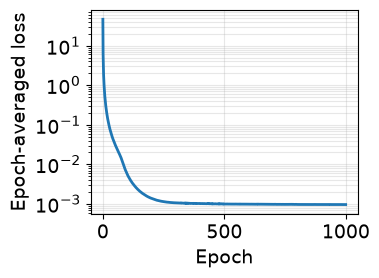

In [8]:
fig, ax = plot_loss(loss_epoch_average)
fig.savefig(output_dir / 'loss.pdf')
plt.show()

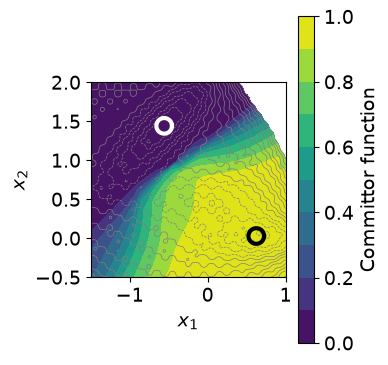

In [9]:
x_grid, y_grid = np.meshgrid(np.linspace(-1.5, 1.0, 801), np.linspace(-0.5, 2.0, 801))
grid_points = torch.zeros((x_grid.size, dimension))
grid_points[:, :2] = torch.from_numpy(np.column_stack((x_grid.ravel(), y_grid.ravel()))).float()
with torch.no_grad():
    v_grid = potential(grid_points).numpy().reshape(x_grid.shape)
q_grid = predict(qmodel, grid_points).reshape(x_grid.shape)
q_grid = np.ma.masked_where(v_grid > 250, q_grid)

t = np.linspace(0, 2*np.pi, 100)
circle = radius * np.column_stack((np.cos(t), np.sin(t)))
boundaries = ((a.numpy() + circle, 'white'), (b.numpy() + circle, 'black'))
fig, ax = plot_committor(
    x_grid, y_grid, q_grid, v_grid,
    potential_levels=np.arange(-150, 251, 25), boundaries=boundaries,
)
fig.savefig(output_dir / 'committor.pdf')
plt.show()
np.savez_compressed(
    output_dir / 'committor_grid.npz', x_grid=x_grid, y_grid=y_grid,
    q=q_grid.filled(np.nan), potential=v_grid,
    fixed_coordinates=np.zeros(dimension - 2),
)


## Committor analysis

Sample $N=50$ points on the $q=0.5$ curve with weights proportional to $e^{-\beta V}$ relative to arc length. Set $N=100$ below for the larger check. Other starting coordinates are zero, as in the plotted slice.

Launch $M=200$ independent trajectories per point under the original 10D Langevin dynamics, with no metadynamics bias. Stop at the first hit of the exact sets $A$ or $B$. Unfinished trajectories are saved and block probability estimation; increase `max_steps` if needed. Reduce `time_step` to check discretization error.

A correct curve should produce a histogram near $0.5$; binomial sampling alone gives a standard deviation of about $0.035$ for $M=200$.
The learned model takes all ten coordinates. The curve is extracted from its zero-extra-coordinate slice, and sampled points are embedded back into ten dimensions before prediction and shooting.


In [10]:
n_analysis_points = 50
shooting_config = ShootingConfig(
    trajectories_per_point=200,
    time_step=1e-5,
    max_steps=1_000_000,
    batch_size=1000,
    seed=1,
    device=str(device),
)
isocommittor_curves = extract_isocommittor(x_grid, y_grid, q_grid)
starting_points = sample_isocommittor(
    isocommittor_curves, potential, beta, n_analysis_points, dimension,
    n_candidates=10_000, seed=1,
)
predicted_committor = predict(qmodel, starting_points.float())
assert starting_points.shape == (n_analysis_points, dimension)
assert torch.count_nonzero(starting_points[:, 2:]) == 0
contour_prediction_error = float(np.max(np.abs(predicted_committor - 0.5)))
print(f'Maximum prediction error on sampled q=0.5 contour: {contour_prediction_error:.3e}')
if contour_prediction_error > 0.01:
    raise RuntimeError('The plotting grid does not resolve the learned isocommittor accurately; increase its resolution.')


Maximum prediction error on sampled q=0.5 contour: 1.182e-04


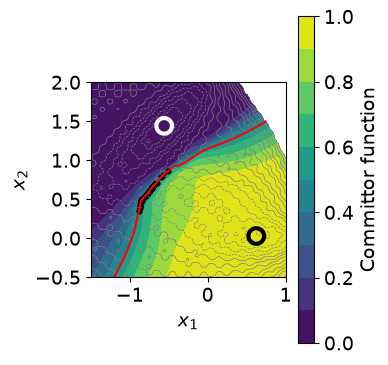

In [11]:
fig, ax = plot_committor(
    x_grid, y_grid, q_grid, v_grid,
    potential_levels=np.arange(-150, 251, 25), boundaries=boundaries,
)
for curve in isocommittor_curves:
    ax.plot(curve[:, 0], curve[:, 1], color='red', linewidth=1.5)
ax.scatter(starting_points[:, 0], starting_points[:, 1], color='black', s=12)
fig.savefig(output_dir / 'isocommittor.pdf')
plt.show()

In [12]:
analysis = committor_analysis(
    potential, starting_points, beta, in_a, in_b, shooting_config,
)
np.savez_compressed(
    output_dir / 'committor_analysis.npz',
    starting_points=starting_points.cpu().numpy(),
    predicted_committor=predicted_committor,
    hits_a=analysis.hits_a,
    hits_b=analysis.hits_b,
    unresolved=analysis.unresolved,
    network_input_dimensions=dimension,
    beta=beta,
    time_step=shooting_config.time_step,
    trajectories_per_point=shooting_config.trajectories_per_point,
    max_steps=shooting_config.max_steps,
    seed=shooting_config.seed,
    device=str(device),
)
probabilities = analysis.probabilities
print(f'Mean: {probabilities.mean():.3f}; standard deviation: {probabilities.std(ddof=1):.3f}')
validation_metrics = {
    'network_input_dimensions': qmodel.network.linear0.in_features,
    'n_starting_points': n_analysis_points,
    'trajectories_per_point': shooting_config.trajectories_per_point,
    'total_trajectories': int((analysis.hits_a + analysis.hits_b + analysis.unresolved).sum()),
    'unresolved': int(analysis.unresolved.sum()),
    'mean_probability': float(probabilities.mean()),
    'sample_standard_deviation': float(probabilities.std(ddof=1)),
    'maximum_contour_prediction_error': contour_prediction_error,
}
(output_dir / 'validation.json').write_text(json.dumps(validation_metrics, indent=2) + '\n')


Trajectories 1-1000: step 10000, 35 still active
Processed 1000/10000 trajectories; 0 unresolved
Trajectories 1001-2000: step 10000, 33 still active
Processed 2000/10000 trajectories; 0 unresolved
Trajectories 2001-3000: step 10000, 43 still active
Trajectories 2001-3000: step 20000, 2 still active
Processed 3000/10000 trajectories; 0 unresolved
Trajectories 3001-4000: step 10000, 37 still active
Trajectories 3001-4000: step 20000, 2 still active
Processed 4000/10000 trajectories; 0 unresolved
Trajectories 4001-5000: step 10000, 25 still active
Processed 5000/10000 trajectories; 0 unresolved
Trajectories 5001-6000: step 10000, 38 still active
Trajectories 5001-6000: step 20000, 2 still active
Processed 6000/10000 trajectories; 0 unresolved
Trajectories 6001-7000: step 10000, 43 still active
Trajectories 6001-7000: step 20000, 1 still active
Processed 7000/10000 trajectories; 0 unresolved
Trajectories 7001-8000: step 10000, 30 still active
Trajectories 7001-8000: step 20000, 3 still act

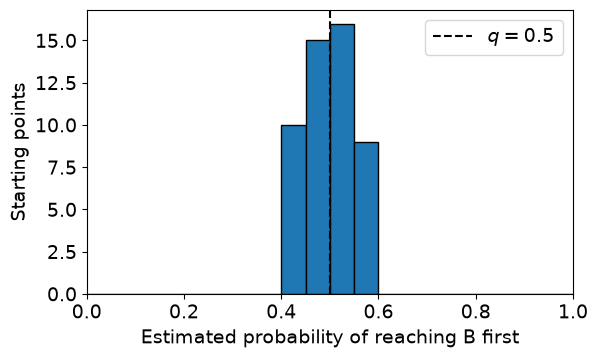

In [13]:
fig, ax = plot_committor_histogram(analysis.probabilities)
fig.savefig(output_dir / 'committor_analysis.pdf')
plt.show()